# Proyecto Machine Learning - Spotify Tracks

## Inteligencia musical y predicción de popularidad de canciones

**Asignatura:** Machine Learning (MLY1101)  
**Caso:** C - Spotify Tracks  
**Integrantes:** Moira Bittner, Lucas Fernandez y Julian Martinez

Este notebook organiza el desarrollo del proyecto utilizando herramientas conocidas de Python como Pandas, NumPy, Matplotlib, Seaborn y Scikit-learn.

El desarrollo se centra en la comprensión del problema, comprensión de los datos, análisis exploratorio, calidad de datos y preparación de los datos, siguiendo la metodología **CRISP-DM**.

**Para ejecutar:** abrir este notebook desde la carpeta `notebooks/` del proyecto y ejecutar todas las celdas en orden. El dataset se lee desde `data/raw/`, el dataset limpio se guarda en `data/processed/` y los gráficos del informe técnico en `images/`.

# 0. Metodología CRISP-DM

El proyecto se organiza según **CRISP-DM**, una metodología de seis fases. En esta evaluación se desarrollan las tres primeras.

| Fase CRISP-DM | Sección del notebook | Estado |
|---|---|---|
| 1. Comprensión del negocio | 1 | Desarrollada |
| 2. Comprensión de los datos | 2 y 3 | Desarrollada |
| 3. Preparación de los datos | 4 | Desarrollada |
| 4. Modelado | - | Próxima etapa |
| 5. Evaluación | - | Próxima etapa |
| 6. Despliegue | - | Próxima etapa |

# 1. Comprensión del negocio

El problema de negocio consiste en analizar las características de las canciones disponibles en el dataset de Spotify para comprender qué factores pueden estar relacionados con su nivel de popularidad.

Como contexto, se plantea el caso de un **sello discográfico o equipo de marketing musical** que debe decidir en qué canciones invertir su presupuesto de promoción. Actualmente esta decisión depende en gran parte de la intuición, lo que puede llevar a invertir en canciones con bajo potencial. Contar con una estimación de popularidad basada en datos permitiría priorizar mejor esa inversión.

La variable principal de interés es `popularity`, que representa la popularidad de cada canción en una escala numérica de 0 a 100. Es una variable numérica discreta (solo toma enteros), pero por su amplio rango (101 valores posibles) se trata como continua, por lo que el problema se aborda como un problema de **regresión supervisada**.

## Objetivo general

Analizar las características musicales y descriptivas de las canciones para identificar patrones y variables que puedan ser útiles posteriormente en la predicción de popularidad.

## 1.1 Objetivos específicos

1. Evaluar la calidad del dataset: valores nulos, duplicados, valores atípicos y registros anómalos.
2. Explorar la distribución de `popularity` y su relación con las características musicales, el género y el contenido explícito.
3. Preparar los datos para el modelamiento: limpieza, codificación, división y escalamiento.
4. Identificar posibles sesgos, riesgos éticos y aspectos de privacidad de los datos.

## 1.2 Definición de KPIs

Se define como **canción de alto potencial** a aquella con `popularity >= 50` (cuartil superior del dataset de modelamiento).

| Nivel | KPI | Meta |
|---|---|---|
| Negocio | Precisión en el top 10 %: de las canciones con mayor popularidad predicha, % que realmente son de alto potencial | > 75,6 % (superar a la regla por género; sección 4.8.7) |
| Modelo | MAE: error promedio en puntos de popularidad | < 9,88 puntos (debe superar a la regla simple "popularidad promedio del género"; sección 4.8.7) |
| Modelo | R² ajustado: variabilidad de `popularity` explicada, penalizada por el número de variables | > 0,431 (superar a la regla por género; sección 4.8.7) |
| Datos | Calidad del dataset preparado | 0 nulos, 0 duplicados y 0 registros de audio inválidos |

**R² vs. R² ajustado.** El R² siempre sube (o se mantiene) al agregar variables, aunque no aporten nada. Como el modelo usará **142 variables** (la mayoría columnas one-hot de género), usamos el **R² ajustado**, que descuenta el número de predictores:

$$R^2_{aj} = 1 - (1 - R^2)\,\frac{n - 1}{n - p - 1}$$

donde $n$ es la cantidad de canciones evaluadas y $p$ la cantidad de variables. Así, una variable que no mejora el ajuste hace bajar el R² ajustado. Con $n = 16.047$ y $p = 142$, alcanzar un R² ajustado de 0,431 exige un R² de aproximadamente 0,436 (sección 4.8.7).

**Justificación de la meta del MAE.** En la versión anterior la meta era un MAE 20 % menor que predecir siempre el promedio. Al calcular las referencias (sección 4.8.7) vimos que eso no era una buena exigencia:

- Predecir siempre el promedio: MAE de **15,19** puntos. Un 20 % menos serían 12,15 puntos.
- Predecir el **promedio del género** de cada canción (una regla sin modelo): MAE de **9,88** puntos, es decir, ya mejora en un 35 % al promedio general.

Por lo tanto, una meta de "20 % menos que el promedio" la cumpliría una regla que cualquier persona del sello puede calcular en una planilla. Un modelo de Machine Learning solo aporta valor si **supera a esa regla**, por lo que la meta queda en **MAE < 9,88**. Con el mismo criterio se fijó la meta del R² ajustado: la regla por género logra **0,431**, así que la meta inicial de 0,35 también quedaba por debajo de una regla sin modelo y se subió a **R² ajustado > 0,431**. El mismo criterio se aplica a la precisión en el top 10 %: elegir las canciones de los géneros con mayor promedio ya logra **75,6 %** de canciones de alto potencial (frente a 26,5 % al azar), por lo que una meta de 60 % la cumpliría la regla sin modelo; la meta queda en **superar 75,6 %**. Esto también tiene sentido para el negocio: 9,88 puntos es menos que la mitad de la distancia entre el primer cuartil (22) y el umbral de alto potencial (50), por lo que el modelo podría distinguir con claridad una canción de baja popularidad de una de alto potencial.

Los KPIs de negocio y modelo se medirán en la etapa de modelado. El KPI de datos se verifica en la sección 4.

# 2. Comprensión de los datos

En esta etapa se carga el dataset, se revisa su estructura, tipos de datos, valores nulos, duplicados y estadísticas principales.

El archivo original `Spotify_Tracks_Dataset.csv` se encuentra en la carpeta `data/raw/` del proyecto.

## Fuente de datos y herramientas utilizadas

Para el desarrollo del proyecto se utiliza el archivo `Spotify_Tracks_Dataset.csv`, correspondiente al caso **Spotify Tracks** proporcionado para esta evaluación. El dataset corresponde al *Spotify Tracks Dataset* publicado en Kaggle (Maharshi Pandya) y contiene información de canciones, artistas, géneros y características musicales obtenidas desde Spotify. La popularidad es calculada por Spotify según la cantidad de reproducciones y qué tan recientes son.

El notebook está preparado para ser trabajado en **Google Colab**, ya que permite ejecutar Python desde el navegador sin instalar nada y, al guardarse en Google Drive, facilita el trabajo compartido entre los integrantes del grupo.

Además, el proyecto completo se sube a un repositorio de **GitHub**, que guarda el historial de cambios de cada integrante y mantiene la estructura de carpetas (datos, notebook, imágenes e informe), de modo que cualquier persona pueda descargar y ejecutar la solución.

Para el análisis se utilizan principalmente:

- **Pandas:** carga, revisión, limpieza y manipulación de datos.
- **NumPy:** apoyo en operaciones numéricas.
- **Matplotlib:** creación de gráficos.
- **Seaborn:** visualización de distribuciones, boxplots y correlaciones.
- **Scikit-learn:** división en entrenamiento/prueba y escalamiento de variables.

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

SEMILLA = 42  # semilla fija para que los resultados sean reproducibles
# Rutas del proyecto: funciona desde la carpeta notebooks/ o desde la raíz del proyecto
RUTA_BASE = ".." if os.path.exists("../data/raw") else "."
RUTA_DATOS_RAW = os.path.join(RUTA_BASE, "data", "raw")
RUTA_DATOS_PROCESADOS = os.path.join(RUTA_BASE, "data", "processed")
RUTA_IMAGENES = os.path.join(RUTA_BASE, "images")

os.makedirs(RUTA_DATOS_PROCESADOS, exist_ok=True)
os.makedirs(RUTA_IMAGENES, exist_ok=True)

In [2]:
# Funciona con la estructura del proyecto (data/raw/) y también subiendo el CSV a Google Colab.
archivo_csv = next((ruta for ruta in [
    os.path.join(RUTA_DATOS_RAW, "Spotify_Tracks_Dataset.csv"),
    "Spotify_Tracks_Dataset.csv",
    "/content/Spotify_Tracks_Dataset.csv",
] if os.path.isfile(ruta)), None)

if archivo_csv is None:
    try:
        from google.colab import files
        print("Sube Spotify_Tracks_Dataset.csv para comenzar.")
        files.upload()
        archivo_csv = "Spotify_Tracks_Dataset.csv"
    except ImportError as exc:
        raise FileNotFoundError("Ubica Spotify_Tracks_Dataset.csv en data/raw/ o junto al notebook") from exc

df = pd.read_csv(archivo_csv)
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 2.1 Dimensiones del dataset

Se revisa la cantidad de filas y columnas para conocer el tamaño del conjunto de datos.

In [3]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])


Filas: 114000
Columnas: 21


El dataset contiene **114.000 registros y 21 columnas**, por lo que existe una cantidad suficiente de información para realizar un análisis exploratorio y, posteriormente, entrenar modelos de Machine Learning.

Cada fila representa un registro asociado a una canción y las columnas contienen información descriptiva y características musicales.

## 2.2 Nombres de las variables

In [4]:
df.columns


Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='str')

## 2.2.1 Diccionario de datos

Para cada variable se indica su tipo en Python, su **clasificación estadística** y su descripción. La clasificación sigue la lógica de numéricas continuas, numéricas discretas, categóricas nominales y categóricas ordinales.

| Variable | Tipo en Python | Clasificación estadística | Descripción |
|---|---|---|---|
| `Unnamed: 0` | int | Identificador (sin valor analítico) | Índice heredado del archivo original |
| `track_id` | texto | Categórica nominal (identificador) | Identificador de la canción en Spotify |
| `artists` | texto | Categórica nominal | Artista(s) de la canción, separados por `;` |
| `album_name` | texto | Categórica nominal | Nombre del álbum |
| `track_name` | texto | Categórica nominal | Nombre de la canción |
| `popularity` | int (0-100) | Numérica discreta | **Variable objetivo.** Popularidad calculada por Spotify según reproducciones y su recencia. Toma solo valores enteros, pero por su amplio rango (101 valores posibles) se trata como continua en la regresión |
| `duration_ms` | int | Numérica continua | Duración en milisegundos. Se registra como entero, pero el tiempo es una magnitud continua |
| `explicit` | bool | Categórica nominal (binaria) | Indica si la canción tiene contenido explícito |
| `danceability` | float (0-1) | Numérica continua | Qué tan bailable es la canción |
| `energy` | float (0-1) | Numérica continua | Intensidad y actividad percibida |
| `key` | int (0-11) | Categórica nominal | Tonalidad musical (0 = Do, 1 = Do♯, ..., 11 = Si). Es un número, pero no tiene orden: Si (11) no es "mayor" que Do (0), las tonalidades son cíclicas |
| `loudness` | float (dB) | Numérica continua | Volumen promedio en decibeles |
| `mode` | int (0/1) | Categórica nominal (binaria) | Modalidad: 1 = mayor, 0 = menor |
| `speechiness` | float (0-1) | Numérica continua | Presencia de palabra hablada |
| `acousticness` | float (0-1) | Numérica continua | Confianza de que la canción sea acústica |
| `instrumentalness` | float (0-1) | Numérica continua | Probabilidad de que no tenga voz |
| `liveness` | float (0-1) | Numérica continua | Probabilidad de que sea una grabación en vivo |
| `valence` | float (0-1) | Numérica continua | Positividad musical (alegre vs. triste) |
| `tempo` | float (BPM) | Numérica continua | Tempo estimado en pulsos por minuto |
| `time_signature` | int | Categórica nominal | Compás estimado (3 a 7 corresponde a 3/4 a 7/4). Aunque los números tienen orden, un compás de 5/4 no es "más" que uno de 4/4 en algún sentido útil para la popularidad, por lo que se trata como nominal |
| `track_genre` | texto | Categórica nominal | Género musical asignado (114 géneros) |

**Variables categóricas ordinales:** el dataset no tiene variables ordinales en su forma original. La única que se construye en el proyecto es la categoría de **alto potencial** (`popularity >= 50`), que define un orden bajo/alto a partir de la variable objetivo y se usa solo para el KPI de negocio.

**Resumen:** 10 numéricas continuas, 1 numérica discreta (la objetivo), 9 categóricas nominales (incluidas 2 binarias y 4 de texto/identificadores) y 1 índice sin valor analítico.

## 2.3 Información general

`info()` permite revisar los nombres de las columnas, tipos de datos y cantidad de valores no nulos.

In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

La revisión general muestra que el dataset combina variables numéricas, booleanas y de texto.

La mayoría de las columnas poseen los **114.000 valores completos**. Las únicas excepciones se encuentran en `artists`, `album_name` y `track_name`, donde falta un registro en cada una. Esto indica que el nivel de datos faltantes es muy bajo.

## 2.4 Estadísticas descriptivas

Se revisan medidas como promedio, desviación estándar, mínimo, máximo y cuartiles de las variables numéricas.

In [6]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500000,32909.109681,0.000,28499.75000,56999.500000,85499.2500,113999.000
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996


La popularidad promedio de las canciones se encuentra cercana a **33 puntos**. También se observa una gran variedad en características como duración, energía, tempo y nivel de volumen.

Estas diferencias son esperables debido a que el dataset contiene canciones pertenecientes a distintos géneros y estilos musicales. Las estadísticas permiten tener una primera idea de la escala y comportamiento de cada variable antes de realizar gráficos y transformaciones.

## 2.5 Valores nulos

Se cuenta la cantidad de valores faltantes por columna.

In [7]:
nulos = df.isnull().sum()
nulos[nulos > 0]


artists       1
album_name    1
track_name    1

Solo se identifican valores nulos en tres columnas:

- `artists`: 1 valor nulo.
- `album_name`: 1 valor nulo.
- `track_name`: 1 valor nulo.

Frente a un total de 114.000 registros, esta cantidad es mínima. Por esta razón, posteriormente es razonable eliminar el registro incompleto sin afectar de manera importante el tamaño del dataset.

## 2.6 Registros duplicados

Primero se revisan filas completamente duplicadas.

In [8]:
print("Filas completamente duplicadas:", df.duplicated().sum())


Filas completamente duplicadas: 0


En esta primera revisión aparecen **0 filas completamente duplicadas**. Sin embargo, todavía existe la columna `Unnamed: 0`, que funciona como un índice diferente para cada fila.

Por esta razón, más adelante se vuelve a revisar la duplicidad después de eliminar esa columna, ya que puede ocultar registros que en el resto de sus variables sí son iguales.

También se revisan identificadores de canciones repetidos. Un `track_id` repetido no se elimina automáticamente, porque una misma canción puede aparecer asociada a más de un género u otra clasificación dentro del dataset.

In [9]:
print("Track ID repetidos:", df["track_id"].duplicated().sum())

df[df["track_id"].duplicated(keep=False)].sort_values("track_id").head(10)


Track ID repetidos: 24259


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,0,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


Se identifican **24.259 apariciones repetidas de `track_id`**. Esto no significa automáticamente que existan 24.259 errores.

Una misma canción puede aparecer más de una vez debido a su clasificación en distintos géneros. Por eso, estos registros se revisan pero no se eliminan únicamente por compartir el mismo `track_id`. La decisión de eliminar duplicados se realizará considerando todas las columnas relevantes.

## 2.7 Valores anómalos en variables musicales

Además de nulos y duplicados, se revisan valores que no tienen sentido musical o que indican que la característica no pudo medirse correctamente.

In [10]:
anomalias = pd.Series({
    "tempo = 0": (df["tempo"] == 0).sum(),
    "danceability = 0": (df["danceability"] == 0).sum(),
    "time_signature = 0": (df["time_signature"] == 0).sum(),
    "time_signature = 1": (df["time_signature"] == 1).sum(),
    "loudness > 0 dB": (df["loudness"] > 0).sum(),
    "duration_ms = 0": (df["duration_ms"] == 0).sum(),
})

pd.DataFrame({"registros": anomalias, "porcentaje": (anomalias / len(df) * 100).round(2)})

,registros,porcentaje
tempo = 0,157,0.14
danceability = 0,157,0.14
time_signature = 0,163,0.14
time_signature = 1,973,0.85
loudness > 0 dB,90,0.08
duration_ms = 0,1,0.00


In [11]:
print("Géneros de las canciones con tempo = 0:")
print(df.loc[df["tempo"] == 0, "track_genre"].value_counts().head(5))
print()
print("Registro con duration_ms = 0:")
df.loc[df["duration_ms"] == 0, ["track_id", "artists", "track_name", "popularity", "track_genre"]]

Géneros de las canciones con tempo = 0:
track_genre
sleep          138
guitar           4
iranian          4
ambient          3
world-music      3
Name: count, dtype: int64

Registro con duration_ms = 0:


,track_id,artists,track_name,popularity,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,0,k-pop


Se identifican **157 canciones con `tempo = 0`**, que coinciden con las 157 que tienen `danceability = 0`. De ellas, **138 pertenecen al género `sleep`** (ruido blanco, sonidos para dormir), donde no existe un pulso musical que medir. También hay **163 registros con `time_signature = 0`**, un compás que no existe.

Estos casos no son errores de digitación, sino características de audio que no pudieron calcularse. Representan solo el **0,14 %** del dataset, por lo que en la preparación para el modelamiento se eliminan (sección 4.8.1).

Los **973 registros con `time_signature = 1`** y los **90 con `loudness` mayor a 0 dB** son poco frecuentes, pero posibles técnicamente, por lo que se mantienen.

El único registro con `duration_ms = 0` es el mismo que tiene los valores nulos en `artists`, `album_name` y `track_name`. Esto confirma que es un registro defectuoso y refuerza la decisión de eliminarlo.

## 2.8 Canciones con popularidad igual a cero

Durante la revisión se observó una cantidad importante de canciones con `popularity = 0`. Como esta es la variable objetivo, se analiza con mayor detalle.

In [12]:
ceros = df["popularity"] == 0
print("Canciones con popularidad 0:", ceros.sum())
print("Porcentaje del dataset:", round(ceros.mean() * 100, 2), "%")

# ¿Los ceros se concentran en canciones que aparecen repetidas?
repetida = df.duplicated(subset=["artists", "track_name"], keep=False)
print()
print("% con popularidad 0 entre canciones con el mismo artista y nombre repetidos:",
      round((df.loc[repetida, "popularity"] == 0).mean() * 100, 1), "%")
print("% con popularidad 0 entre canciones sin repetición:",
      round((df.loc[~repetida, "popularity"] == 0).mean() * 100, 1), "%")

Canciones con popularidad 0: 16020
Porcentaje del dataset: 14.05 %

% con popularidad 0 entre canciones con el mismo artista y nombre repetidos: 27.0 %
% con popularidad 0 entre canciones sin repetición: 4.3 %


In [13]:
ceros_genero = (
    df.groupby("track_genre")["popularity"]
    .agg(
        popularidad_media="mean",
        pct_ceros=lambda s: (s == 0).mean() * 100,
        popularidad_media_sin_ceros=lambda s: s[s > 0].mean(),
    )
    .round(2)
    .sort_values("pct_ceros", ascending=False)
)

print("Géneros con 30 % o más de canciones con popularidad 0:", (ceros_genero["pct_ceros"] >= 30).sum())
ceros_genero.head(10)

Géneros con 30 % o más de canciones con popularidad 0: 19


,popularidad_media,pct_ceros,popularidad_media_sin_ceros
track_genre,,,
jazz,13.63,68.1,42.72
iranian,2.21,65.6,6.42
romance,3.24,63.6,8.91
soul,19.80,61.1,50.89
latin,8.30,58.8,20.14
country,17.03,58.7,41.23
rock,19.00,52.5,40.00
dance,22.69,49.0,44.49
alternative,24.34,48.5,47.26


Hay **16.020 canciones con popularidad 0**, equivalentes al **14,05 %** del dataset, y no se distribuyen de manera uniforme:

- Entre las canciones cuyo artista y nombre se repiten (por ejemplo, la misma canción en un álbum y en un recopilatorio), el **27,0 %** tiene popularidad 0, frente al **4,3 %** de las que no se repiten.
- **19 géneros** tienen 30 % o más de ceros. Por ejemplo, `iranian`, `romance` y `latin`, que aparecen entre los géneros menos populares, tienen cerca del 60 % de sus canciones con popularidad 0.

Por lo tanto, un 0 no siempre significa que la canción no se escuche: puede ser una canción nueva que todavía no acumula reproducciones o una versión duplicada (recopilatorio) cuyas reproducciones se registran en otra versión. En ambos casos el 0 refleja **falta de medición**, no baja popularidad.

**Decisión:** se mantienen en el dataset limpio general (para no perder la información), pero **se excluyen del dataset de modelamiento** (sección 4.8.2), porque enseñarle al modelo que esas canciones tienen popularidad 0 sería enseñarle un valor que no corresponde a su popularidad real.

## 2.9 Balance de géneros

In [14]:
conteo_generos = df["track_genre"].value_counts()

print("Cantidad de géneros:", conteo_generos.shape[0])
print("Canciones por género (mínimo):", conteo_generos.min())
print("Canciones por género (máximo):", conteo_generos.max())

Cantidad de géneros: 114
Canciones por género (mínimo): 1000
Canciones por género (máximo): 1000


El dataset contiene **114 géneros con exactamente 1.000 canciones cada uno**. Esto muestra que los datos fueron recolectados con un muestreo fijo por género y **no representan la proporción real** de géneros en Spotify ni en lo que escuchan los usuarios. Este punto se considera en la evaluación de sesgos (sección 5).

## 2.10 Resumen de calidad de datos

| Aspecto revisado | Resultado | Acción |
|---|---|---|
| Valores nulos | 1 registro con nulos en 3 columnas (y `duration_ms = 0`) | Eliminar (sección 4.2) |
| Columna índice `Unnamed: 0` | Sin valor analítico y oculta duplicados | Eliminar (sección 4.1) |
| Filas duplicadas | 0 al inicio, 450 al quitar `Unnamed: 0` | Eliminar (sección 4.3) |
| `track_id` repetidos | 24.259 repeticiones (misma canción en varios géneros) | Una fila por canción para modelar (sección 4.8.3) |
| `tempo = 0` / `time_signature = 0` | 163 registros, audio no medible | Eliminar para modelar (sección 4.8.1) |
| `popularity = 0` | 16.020 registros (14,05 %) | Excluir del dataset de modelamiento (sección 4.8.2) |
| Duración atípica (IQR) | 5.617 registros (4,93 %) | Mantener y aplicar logaritmo (secciones 3.9, 3.10 y 4.8.5) |
| Atípicos en otras variables | `speechiness`, `instrumentalness`, `liveness` y `loudness` con muchos atípicos por IQR | Mantener: son valores válidos de distribuciones asimétricas (sección 3.10) |
| Géneros balanceados artificialmente | 1.000 canciones por género | No representa el catálogo real, pero es positivo para el modelo porque ningún género domina el aprendizaje (sección 5) |

# 3. Análisis exploratorio de datos (EDA)

El objetivo del EDA es comprender la distribución de las variables, identificar patrones, posibles anomalías y relaciones que puedan ser útiles para etapas posteriores.

## 3.1 Distribución de la popularidad

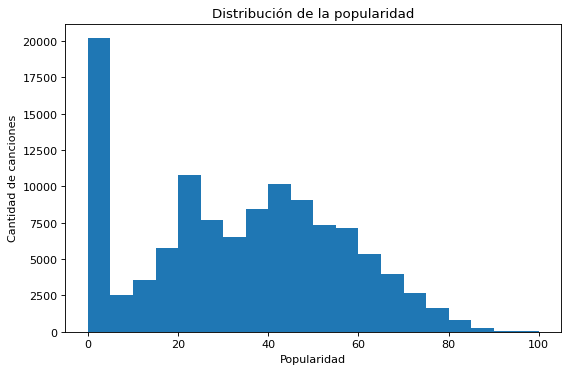

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(df["popularity"], bins=20)
plt.title("Distribución de la popularidad")
plt.xlabel("Popularidad")
plt.ylabel("Cantidad de canciones")
plt.savefig(os.path.join(RUTA_IMAGENES, "distribucion_popularidad.png"), bbox_inches="tight")
plt.show()


In [16]:
print("Popularidad promedio:", round(df["popularity"].mean(), 2))
print("Mediana de popularidad:", df["popularity"].median())
print("Popularidad mínima:", df["popularity"].min())
print("Popularidad máxima:", df["popularity"].max())


Popularidad promedio: 33.24
Mediana de popularidad: 35.0
Popularidad mínima: 0
Popularidad máxima: 100


La popularidad promedio es de **33,24**, mientras que la mediana es **35**. El valor mínimo es **0** y el máximo es **100**.

Además, el 25 % de las canciones posee una popularidad de **17 o menos**, mientras que el 75 % presenta una popularidad de **50 o menos**.

El histograma muestra que la popularidad se encuentra distribuida en distintos niveles y que existe una cantidad importante de canciones con valores bajos. Esto indica que el dataset no está compuesto solamente por canciones muy populares.

## 3.2 Boxplot de popularidad

El boxplot ayuda a observar la dispersión de la variable y posibles valores extremos.

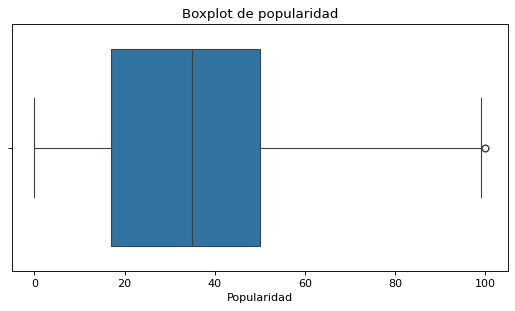

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="popularity")
plt.title("Boxplot de popularidad")
plt.xlabel("Popularidad")
plt.show()


El boxplot confirma que existe una dispersión amplia en los valores de popularidad. La mitad central de las canciones se encuentra aproximadamente entre **17 y 50 puntos de popularidad**.

No se observa que la popularidad esté concentrada en un único nivel, lo que resulta útil para el proyecto porque existe variabilidad suficiente para estudiar qué características podrían relacionarse con esta variable.

## 3.3 Distribución de variables musicales

Se seleccionan algunas características musicales relevantes para observar sus distribuciones.

In [18]:
variables_musicales = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

df[variables_musicales].describe().T


,count,mean,std,min,25%,50%,75%,max
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.00000,0.000042,0.0490,1.000
liveness,114000.0,0.213553,0.190378,0.000,0.09800,0.132000,0.2730,1.000
valence,114000.0,0.474068,0.259261,0.000,0.26000,0.464000,0.6830,0.995
tempo,114000.0,122.147837,29.978197,0.000,99.21875,122.017000,140.0710,243.372


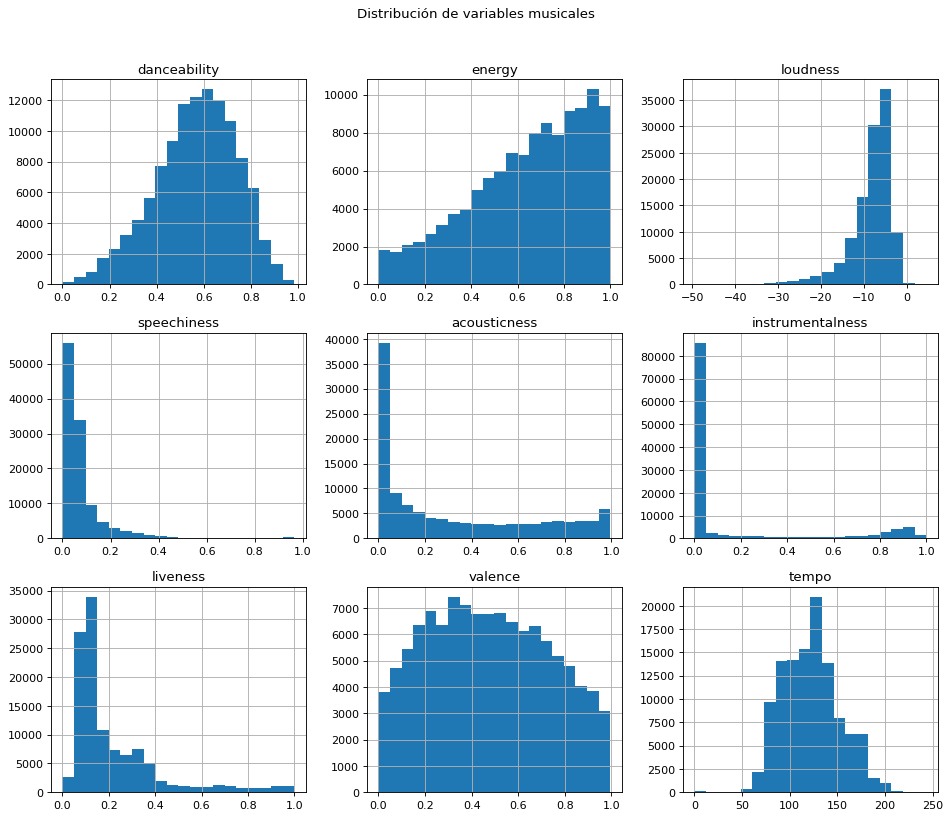

In [19]:
df[variables_musicales].hist(figsize=(12, 10), bins=20)
plt.suptitle("Distribución de variables musicales", y=1.02)
plt.tight_layout()
plt.show()


Las variables presentan comportamientos diferentes:

- `danceability` tiene un promedio cercano a **0,57**, por lo que gran parte de las canciones presenta un nivel intermedio de bailabilidad.
- `energy` tiene un promedio aproximado de **0,64**, mostrando una presencia importante de canciones con energía media o alta.
- `speechiness` e `instrumentalness` concentran muchos valores bajos.
- `valence` se encuentra cercana a un nivel medio, con promedio aproximado de **0,47**.
- `tempo` presenta un promedio cercano a **122 BPM**.

Estas diferencias muestran que las canciones poseen características musicales variadas y justifican analizar posteriormente cuáles de ellas aportan información para explicar la popularidad.

## 3.4 Matriz de correlación

Se utiliza una matriz de correlación para observar relaciones lineales entre variables numéricas. La correlación no implica causalidad.

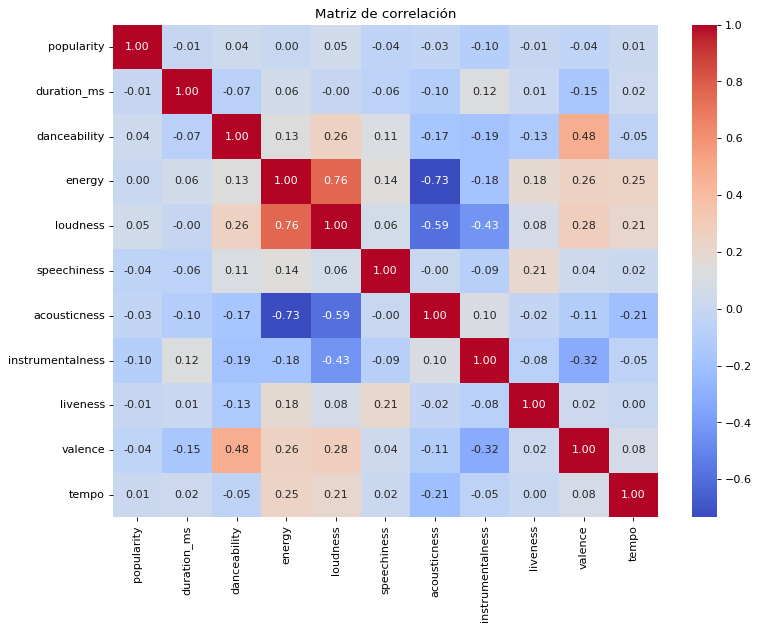

In [20]:
variables_correlacion = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

correlacion = df[variables_correlacion].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlacion, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación")
plt.savefig(os.path.join(RUTA_IMAGENES, "matriz_correlacion.png"), bbox_inches="tight")
plt.show()


In [21]:
correlacion["popularity"].sort_values(ascending=False)


popularity          1.000000
loudness            0.050423
danceability        0.035448
tempo               0.013205
energy              0.001056
liveness           -0.005387
duration_ms        -0.007101
acousticness       -0.025472
valence            -0.040534
speechiness        -0.044927
instrumentalness   -0.095139

Las correlaciones entre `popularity` y las características musicales son en general **bajas**.

Las relaciones más altas con popularidad dentro de las variables analizadas son:

- `instrumentalness`: aproximadamente **-0,10**.
- `loudness`: aproximadamente **0,05**.
- `danceability`: aproximadamente **0,04**.

Estos valores son cercanos a cero, por lo que ninguna de estas variables presenta por sí sola una relación lineal fuerte con la popularidad.

En cambio, sí aparecen relaciones importantes entre algunas características musicales. Por ejemplo, `energy` y `loudness` presentan una correlación positiva alta, mientras que `energy` y `acousticness` presentan una correlación negativa alta.

Esto sugiere que la popularidad probablemente no depende de una sola característica y que un futuro modelo debería considerar varias variables en conjunto.

Hay que considerar que la correlación de Pearson **solo mide relaciones lineales**. Una correlación cercana a cero no descarta que exista una relación curva. Esto se comprueba en la sección 3.4.1. Las correlaciones altas entre variables predictoras (`energy`, `loudness` y `acousticness`) se analizan como posible multicolinealidad en la sección 3.4.2.


## 3.4.1 Comprobación de linealidad

La matriz anterior usa la correlación de **Pearson**, que supone una relación lineal (una recta). Para comprobar si ese supuesto es razonable se hacen dos revisiones sobre el dataset de canciones con audio válido y popularidad mayor a 0 (el mismo criterio usado para modelar en la sección 4.8):

1. **Pearson vs. Spearman:** Spearman mide relaciones monótonas (que siempre suben o siempre bajan, aunque no sea en línea recta). Si Spearman es claramente distinta de Pearson, la relación no es lineal.
2. **Ajuste lineal vs. cuadrático:** se compara el R² de una recta con el R² de una curva de grado 2 para cada variable. Si la curva explica bastante más, la relación tiene curvatura.

También se grafica la popularidad promedio por **decil** de cada variable: si la relación fuera lineal, los puntos formarían una recta.


In [22]:

df_lin = df[(df["tempo"] > 0) & (df["time_signature"] > 0) & (df["popularity"] > 0)].copy()
df_lin["duration_min"] = df_lin["duration_ms"] / 60000

variables_continuas = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "duration_min"
]

filas = []
for var in variables_continuas:
    x, y_pop = df_lin[var], df_lin["popularity"]
    pearson = x.corr(y_pop)
    spearman = x.corr(y_pop, method="spearman")
    r2_lineal = pearson ** 2
    coef = np.polyfit(x, y_pop, 2)
    r2_cuadratico = 1 - np.var(y_pop - np.polyval(coef, x)) / np.var(y_pop)
    filas.append([var, pearson, spearman, r2_lineal, r2_cuadratico])

linealidad = pd.DataFrame(
    filas, columns=["variable", "pearson", "spearman", "r2_lineal", "r2_cuadratico"]
).set_index("variable")
linealidad["ganancia_curva"] = linealidad["r2_cuadratico"] - linealidad["r2_lineal"]
linealidad.round(4).sort_values("ganancia_curva", ascending=False)


,pearson,spearman,r2_lineal,r2_cuadratico,ganancia_curva
variable,,,,,
acousticness,-0.0091,0.0475,0.0001,0.0151,0.0150
energy,-0.0338,-0.0665,0.0011,0.0158,0.0147
danceability,0.0617,0.0534,0.0038,0.0122,0.0084
valence,-0.0133,-0.0144,0.0002,0.0067,0.0066
loudness,0.0721,0.0670,0.0052,0.0065,0.0014
instrumentalness,-0.1821,-0.1699,0.0332,0.0342,0.0011
tempo,-0.0185,-0.0178,0.0003,0.0007,0.0003
duration_min,-0.0527,-0.0277,0.0028,0.0029,0.0001
speechiness,-0.0904,-0.1038,0.0082,0.0082,0.0000


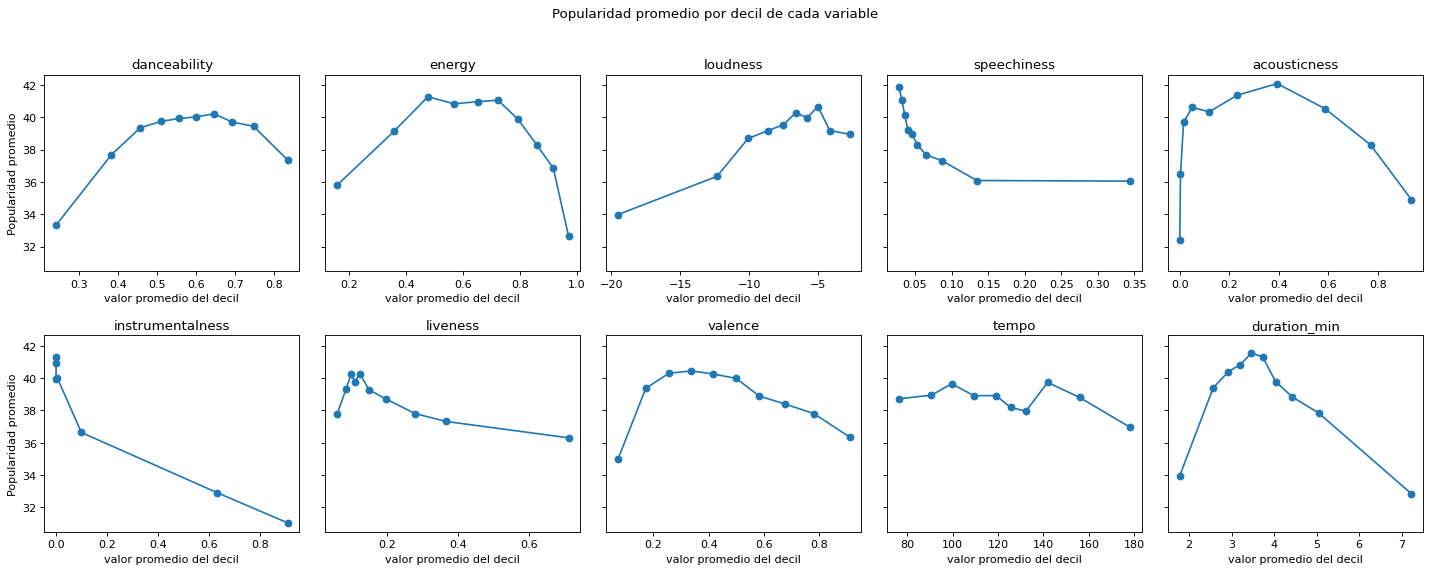

In [23]:

fig, ejes = plt.subplots(2, 5, figsize=(18, 7), sharey=True)
for eje, var in zip(ejes.ravel(), variables_continuas):
    deciles = pd.qcut(df_lin[var], 10, duplicates="drop")
    promedio = df_lin.groupby(deciles, observed=True).agg(x=(var, "mean"), pop=("popularity", "mean"))
    eje.plot(promedio["x"], promedio["pop"], marker="o")
    eje.set_title(var)
    eje.set_xlabel("valor promedio del decil")
ejes[0, 0].set_ylabel("Popularidad promedio")
ejes[1, 0].set_ylabel("Popularidad promedio")
plt.suptitle("Popularidad promedio por decil de cada variable", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "linealidad_deciles.png"), bbox_inches="tight")
plt.show()



**Resultados:**

- Todas las relaciones son débiles: el R² individual más alto es el de `instrumentalness` (cerca de 0,04).
- **Sí hay relaciones no lineales.** `acousticness` tiene una correlación de Pearson prácticamente 0 (-0,01), pero su ajuste cuadrático explica cerca de un 1,5 % de la variabilidad y su Spearman tiene el signo contrario (+0,05): la popularidad es más alta en los valores intermedios y baja en ambos extremos, por lo que los efectos de subida y bajada se cancelan en una recta. `energy` muestra el mismo patrón (su R² pasa de 0,001 a 0,016 con la curva), y `danceability` y `valence` también mejoran con la curva.
- En el gráfico por deciles se ve que varias relaciones tienen forma de **"U invertida"**: `danceability`, `energy`, `acousticness`, `valence` y `duration_min` alcanzan su mayor popularidad en valores intermedios (por ejemplo, las canciones de unos 3,5 minutos son las más populares y las muy cortas o muy largas, las menos). `speechiness` baja de forma curva y se estabiliza, mientras que `instrumentalness` y `loudness` se parecen más a una recta. En `duration_min` el ajuste cuadrático casi no mejora porque la variable es muy asimétrica (sección 3.10), pero la curva por deciles sí muestra la forma no lineal.

**Conclusión:** el supuesto de linealidad no se cumple para todas las variables, por lo que la matriz de correlación **subestima** la relación de algunas variables con la popularidad. Para la etapa de modelado esto implica:

- Probar modelos que capturen relaciones no lineales (por ejemplo, árboles de decisión, Random Forest o Gradient Boosting).
- Si se usa regresión lineal, agregar términos cuadráticos para `energy`, `acousticness`, `danceability` y `valence`.



## 3.4.2 Multicolinealidad entre variables musicales

En la matriz de correlación aparecen variables predictoras muy relacionadas entre sí. Cuando dos o más predictoras están muy correlacionadas (**multicolinealidad**), un modelo lineal no puede separar bien el efecto de cada una: los coeficientes se vuelven inestables y difíciles de interpretar, aunque la predicción total no necesariamente empeore.

Se revisan los pares con |r| ≥ 0,5 y se calcula el **VIF** (*Variance Inflation Factor*) de cada variable continua. El VIF indica cuánto aumenta la varianza del coeficiente de una variable por estar relacionada con las demás. Como regla habitual, un VIF mayor a 5 indica multicolinealidad preocupante y mayor a 10, grave.


In [24]:

from sklearn.linear_model import LinearRegression

corr_pred = df_lin[variables_continuas].corr()
pares = (
    corr_pred.where(np.triu(np.ones(corr_pred.shape, dtype=bool), k=1))
    .stack()
    .rename("correlacion")
    .to_frame()
)
print("Pares de variables con |r| >= 0,5:")
print(pares[pares["correlacion"].abs() >= 0.5].round(2).sort_values("correlacion"))

# VIF = 1 / (1 - R²) al predecir cada variable con las demás
vif = {}
for var in variables_continuas:
    otras = [v for v in variables_continuas if v != var]
    r2 = LinearRegression().fit(df_lin[otras], df_lin[var]).score(df_lin[otras], df_lin[var])
    vif[var] = 1 / (1 - r2)

print()
print("VIF por variable:")
pd.Series(vif, name="VIF").round(2).sort_values(ascending=False)


Pares de variables con |r| >= 0,5:
                       correlacion
energy   acousticness        -0.73
loudness acousticness        -0.58
energy   loudness             0.76

VIF por variable:


energy              4.24
loudness            3.25
acousticness        2.38
valence             1.54
danceability        1.46
instrumentalness    1.46
liveness            1.15
speechiness         1.13
tempo               1.09
duration_min        1.05


**Resultados:**

- Pares más relacionados: `energy` y `loudness` (r ≈ 0,76), `energy` y `acousticness` (r ≈ -0,73) y `loudness` y `acousticness` (r ≈ -0,59). Tiene sentido musical: una canción con más energía suele ser más fuerte y menos acústica, así que las tres variables miden en parte lo mismo.
- El VIF más alto es el de `energy` (≈ 4,2), seguido de `loudness` (≈ 3,3) y `acousticness` (≈ 2,4). Ninguna supera 5, por lo que la multicolinealidad es **moderada**, no grave. `energy` es la variable más explicada por las demás.

**Decisión:** por ahora **no se elimina ninguna variable**, porque:

1. Ningún VIF supera el umbral de 5.
2. Como vimos en la sección 3.4.1, `energy` y `acousticness` tienen relaciones no lineales con la popularidad que la otra variable no reemplaza por completo.
3. Los modelos basados en árboles no se ven afectados por la multicolinealidad en su capacidad de predicción.

En la etapa de modelado, si se usa **regresión lineal**, se probará (a) eliminar `energy`, que es la más redundante, o (b) usar regresión **Ridge**, que reduce la inestabilidad de los coeficientes. Además, al interpretar la importancia de las variables habrá que considerar que el efecto de `energy`, `loudness` y `acousticness` se reparte entre las tres.


## 3.5 Popularidad promedio por género

Se calcula la popularidad promedio para cada género musical y se muestran los diez géneros con mayor promedio.

In [25]:
popularidad_genero = (
    df.groupby("track_genre")["popularity"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

popularidad_genero


track_genre
pop-film     59.283
k-pop        56.896
chill        53.651
sad          52.379
grunge       49.594
indian       49.539
anime        48.772
emo          48.128
sertanejo    47.866
pop          47.576

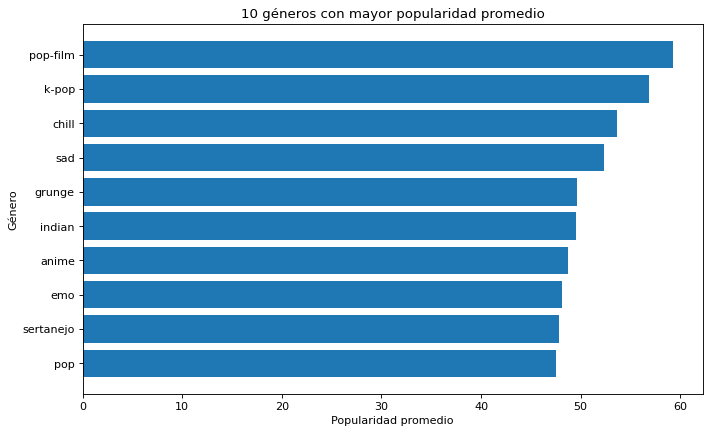

In [26]:
plt.figure(figsize=(10, 6))
plt.barh(popularidad_genero.index[::-1], popularidad_genero.values[::-1])
plt.title("10 géneros con mayor popularidad promedio")
plt.xlabel("Popularidad promedio")
plt.ylabel("Género")
plt.savefig(os.path.join(RUTA_IMAGENES, "popularidad_por_genero.png"), bbox_inches="tight")
plt.show()


Los géneros con mayor popularidad promedio dentro del dataset son encabezados por:

- `pop-film`: **59,28**
- `k-pop`: **56,90**
- `chill`: **53,65**
- `sad`: **52,38**
- `grunge`: **49,59**

Se observan diferencias claras entre géneros. Esto indica que el género musical puede aportar información importante para comprender la popularidad.

Sin embargo, estos resultados corresponden a promedios dentro de este dataset y no significan que todas las canciones de esos géneros sean necesariamente más populares.

## 3.6 Contenido explícito y popularidad

Se compara la distribución de popularidad entre canciones marcadas como explícitas y no explícitas.

In [27]:
df.groupby("explicit")["popularity"].agg(["count", "mean", "median"])


,count,mean,median
explicit,,,
False,104253,32.937891,34.0
True,9747,36.454191,37.0


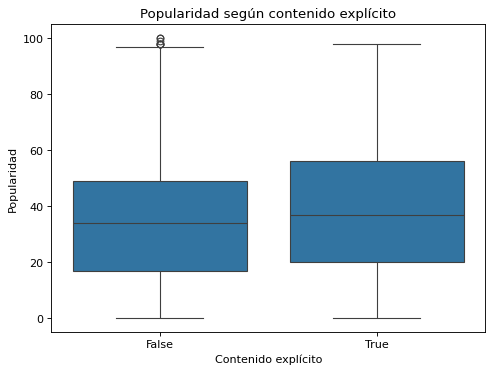

In [28]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="explicit", y="popularity")
plt.title("Popularidad según contenido explícito")
plt.xlabel("Contenido explícito")
plt.ylabel("Popularidad")
plt.show()


Las canciones no explícitas tienen una popularidad promedio de aproximadamente **32,94**, mientras que las canciones explícitas alcanzan cerca de **36,45**.

La diferencia es de alrededor de **3,5 puntos** a favor de las canciones explícitas dentro de este conjunto de datos.

El gráfico permite observar esta diferencia, pero no se puede concluir que el contenido explícito cause una mayor popularidad. Pueden existir otros factores asociados, como género, artista o tipo de audiencia.

## 3.7 Danceability y popularidad

Para evitar cargar el gráfico con 114.000 puntos, se utiliza una muestra de 5.000 registros solo para la visualización.

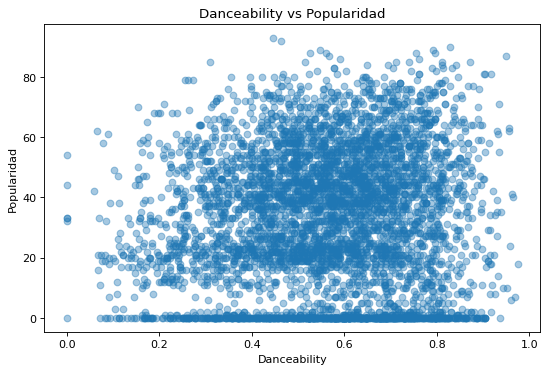

In [29]:
muestra = df.sample(5000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(muestra["danceability"], muestra["popularity"], alpha=0.4)
plt.title("Danceability vs Popularidad")
plt.xlabel("Danceability")
plt.ylabel("Popularidad")
plt.show()


La nube de puntos se encuentra bastante dispersa y no muestra una tendencia claramente creciente o decreciente.

Esto coincide con la baja correlación encontrada entre `danceability` y `popularity`. Por lo tanto, una canción con mayor nivel de bailabilidad no necesariamente tendrá una popularidad mayor.

Esta variable puede seguir siendo útil cuando se combina con otras características, pero por sí sola no explica bien la popularidad.

## 3.8 Energy y popularidad

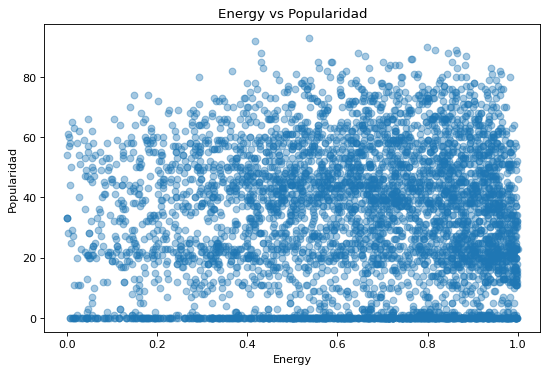

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(muestra["energy"], muestra["popularity"], alpha=0.4)
plt.title("Energy vs Popularidad")
plt.xlabel("Energy")
plt.ylabel("Popularidad")
plt.show()


El gráfico presenta una gran dispersión de valores de popularidad para distintos niveles de energía.

No se observa una relación lineal clara entre ambas variables, lo que coincide con la correlación cercana a cero obtenida anteriormente.

Por lo tanto, `energy` por sí sola no parece suficiente para explicar la popularidad de una canción.

## 3.9 Revisión de posibles valores atípicos en duración

Se utiliza el rango intercuartílico (IQR) para identificar duraciones que se alejan considerablemente de la mayoría de las canciones. Estos registros se identifican, pero no se eliminan automáticamente sin una justificación.

In [31]:
Q1 = df["duration_ms"].quantile(0.25)
Q3 = df["duration_ms"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

atipicos_duracion = df[
    (df["duration_ms"] < limite_inferior) |
    (df["duration_ms"] > limite_superior)
]

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Cantidad de posibles valores atípicos:", len(atipicos_duracion))


Límite inferior: 42906.0
Límite superior: 392666.0
Cantidad de posibles valores atípicos: 5617


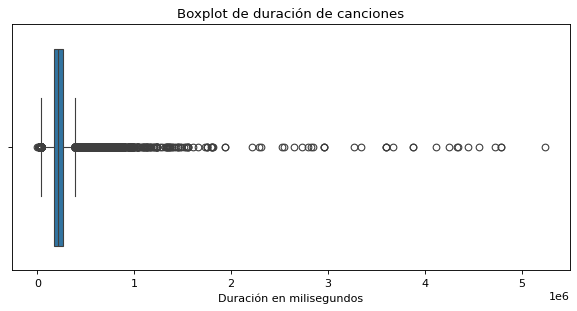

In [32]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="duration_ms")
plt.title("Boxplot de duración de canciones")
plt.xlabel("Duración en milisegundos")
plt.show()


Utilizando el método del rango intercuartílico se identifican **5.617 registros** fuera de los límites calculados, equivalentes a aproximadamente **4,9 % del dataset**.

Estos valores corresponden principalmente a canciones con duraciones considerablemente diferentes a la mayoría. No se eliminan automáticamente, ya que una canción muy corta o muy larga puede ser un registro válido y no necesariamente un error.

Antes de remover valores atípicos siempre es necesario analizar si representan errores o casos reales.


## 3.10 Valores atípicos en todas las variables continuas

La sección 3.9 revisó solo la duración. Aquí se aplica la identificación de atípicos a **todas las variables continuas y a la variable objetivo**, con dos métodos:

- **IQR:** valores bajo $Q_1 - 1,5 \cdot IQR$ o sobre $Q_3 + 1,5 \cdot IQR$.
- **Puntaje Z:** valores a más de 3 desviaciones estándar de la media ($|z| > 3$). Este método supone una distribución aproximadamente simétrica, por eso se compara con el IQR.

También se calcula la **asimetría** (*skewness*): valores mayores a 1 o menores a -1 indican una distribución muy asimétrica, donde el IQR marca muchos "atípicos" que en realidad son la cola normal de la variable.

Se usa el mismo dataset de la sección 3.4.1 (audio válido y popularidad mayor a 0).


In [33]:

variables_atipicos = ["popularity"] + variables_continuas

filas = []
for var in variables_atipicos:
    x = df_lin[var]
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    atip_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    atip_z = (np.abs((x - x.mean()) / x.std()) > 3).sum()
    filas.append([var, x.min(), x.max(), atip_iqr, atip_iqr / len(x) * 100, atip_z, atip_z / len(x) * 100, x.skew()])

atipicos = pd.DataFrame(
    filas, columns=["variable", "min", "max", "atipicos_iqr", "pct_iqr", "atipicos_z", "pct_z", "asimetria"]
).set_index("variable")
atipicos.round(2)


,min,max,atipicos_iqr,pct_iqr,atipicos_z,pct_z,asimetria
variable,,,,,,,
popularity,1.00,100.00,3,0.00,18,0.02,0.06
danceability,0.05,0.98,443,0.45,1,0.00,-0.36
energy,0.00,1.00,0,0.00,0,0.00,-0.59
loudness,-46.59,4.53,4983,5.09,2121,2.17,-1.97
speechiness,0.02,0.96,11413,11.67,1776,1.82,4.58
acousticness,0.00,1.00,0,0.00,0,0.00,0.73
instrumentalness,0.00,1.00,21528,22.01,0,0.00,1.65
liveness,0.01,1.00,7641,7.81,3159,3.23,2.06
valence,0.00,1.00,0,0.00,0,0.00,0.14


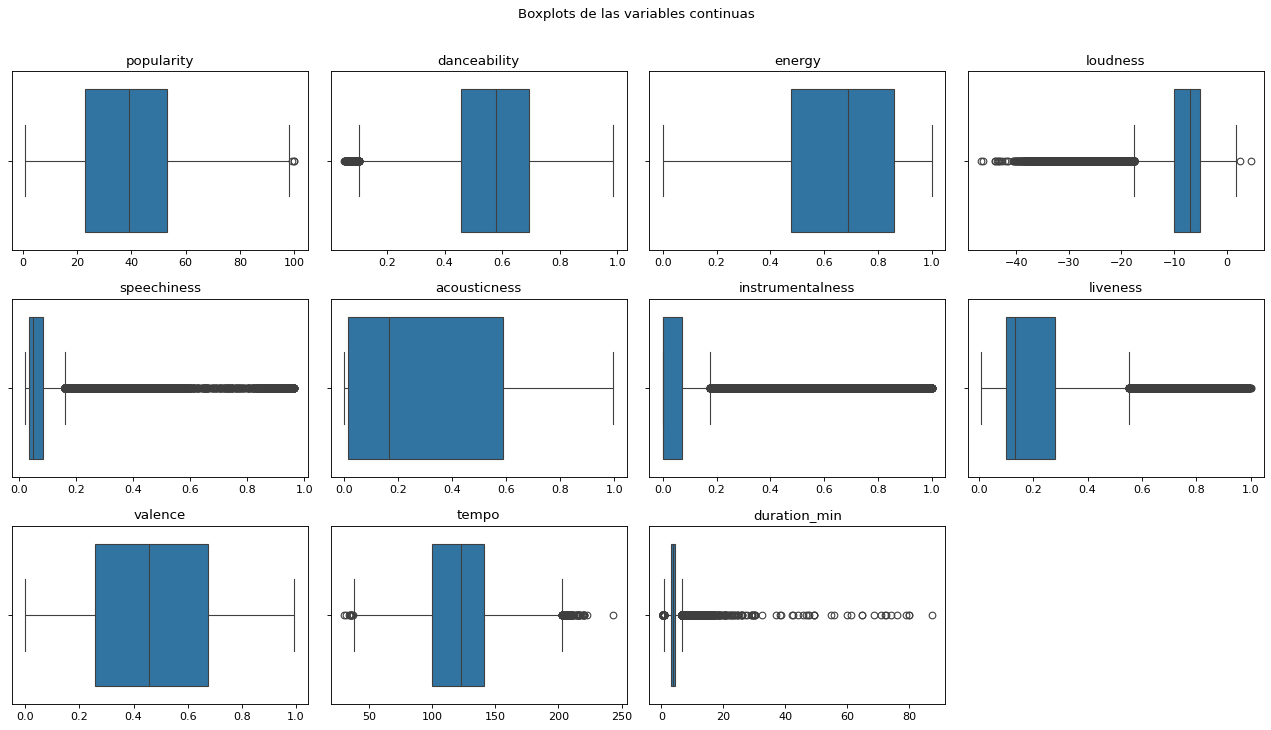

In [34]:

fig, ejes = plt.subplots(3, 4, figsize=(16, 9))
for eje, var in zip(ejes.ravel(), variables_atipicos):
    sns.boxplot(x=df_lin[var], ax=eje)
    eje.set_title(var)
    eje.set_xlabel("")
for eje in ejes.ravel()[len(variables_atipicos):]:
    eje.axis("off")
plt.suptitle("Boxplots de las variables continuas", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "boxplots_atipicos.png"), bbox_inches="tight")
plt.show()


In [35]:

# Efecto de aplicar logaritmo a la duración
duracion_log = np.log(df_lin["duration_min"])
print("Asimetría de duration_min:", round(df_lin["duration_min"].skew(), 2))
print("Asimetría de log(duration_min):", round(duracion_log.skew(), 2))
print("Atípicos |z| > 3 en duration_min:", (np.abs((df_lin["duration_min"] - df_lin["duration_min"].mean()) / df_lin["duration_min"].std()) > 3).sum())
print("Atípicos |z| > 3 en log(duration_min):", (np.abs((duracion_log - duracion_log.mean()) / duracion_log.std()) > 3).sum())


Asimetría de duration_min: 11.34
Asimetría de log(duration_min): -0.34
Atípicos |z| > 3 en duration_min: 780
Atípicos |z| > 3 en log(duration_min): 1457



**Resultados y decisiones por variable:**

| Variable | Qué se observa | Decisión |
|---|---|---|
| `popularity` (objetivo) | Solo 3 atípicos por IQR y 18 por Z (0,02 %); distribución casi simétrica (asimetría 0,06) | **Mantener.** La variable a predecir no tiene atípicos que distorsionen el modelo; los valores cercanos a 100 son canciones reales muy populares |
| `danceability`, `energy`, `acousticness`, `valence`, `tempo` | Muy pocos o ningún atípico | Mantener sin cambios |
| `loudness` | Cola larga hacia volúmenes muy bajos (asimetría negativa) | Mantener: son canciones suaves o ambientales reales, y el rango en dB es válido |
| `speechiness`, `liveness` | Muchos atípicos por IQR (asimetría alta): la mayoría de las canciones está cerca de 0 y los valores altos corresponden a podcasts/rap o grabaciones en vivo | Mantener: están dentro del rango 0-1 y describen un tipo real de pista |
| `instrumentalness` | 22 % marcado como atípico por IQR, pero 0 por Z | Mantener: más de la mitad de las canciones tiene valor ~0 (con voz), por lo que el IQR es casi 0 y cualquier canción instrumental queda "fuera". Es un efecto del método, no un error |
| `duration_min` | Asimetría muy alta (11,34) y canciones de hasta 87 minutos | **Transformar con logaritmo** (sección 4.8.5): la asimetría baja a -0,34 sin eliminar canciones válidas. Los atípicos por Z suben (de 780 a 1.457), porque ahora la distribución es simétrica y aparecen en ambas colas, pero ya no son valores extremos que dominen la escala: una canción de 87 minutos pasa de estar a más de 40 desviaciones estándar a estar a unas 8 |

**Conclusión:** no se eliminan registros por ser atípicos, porque todos los valores son posibles dentro de la escala de cada variable y representan tipos reales de canciones. La única transformación necesaria es el **logaritmo de la duración**, porque es la variable con asimetría extrema y, al escalarla con `StandardScaler`, unas pocas canciones muy largas dominarían la media y la desviación estándar. Para la etapa de modelado, los modelos basados en árboles son además poco sensibles a los atípicos.



## 3.11 Una misma canción clasificada en varios géneros

En la sección 2.6 se vio que hay `track_id` repetidos. Aquí se revisa qué cambia entre las copias de una misma canción.


In [36]:

generos_por_cancion = df_lin.groupby("track_id")["track_genre"].nunique()
multi = generos_por_cancion[generos_por_cancion > 1]

print("Canciones únicas:", generos_por_cancion.shape[0])
print("Canciones en 2 o más géneros:", multi.shape[0], f"({multi.shape[0] / generos_por_cancion.shape[0] * 100:.1f} %)")
print("Máximo de géneros para una misma canción:", generos_por_cancion.max())

copias = df_lin[df_lin["track_id"].isin(multi.index)]
columnas_revisar = variables_continuas + ["popularity"]
varia = copias.groupby("track_id")[columnas_revisar].nunique().gt(1).mean() * 100
print()
print("% de canciones repetidas en que el valor cambia entre sus copias:")
print(varia.round(1))
print()
print("Ejemplo de combinaciones de géneros más frecuentes:")
print(copias.groupby("track_id")["track_genre"].apply(lambda g: " + ".join(sorted(g))).value_counts().head(8))


Canciones únicas: 80235
Canciones en 2 o más géneros: 12640 (15.8 %)
Máximo de géneros para una misma canción: 9

% de canciones repetidas en que el valor cambia entre sus copias:
danceability        0.0
energy              0.0
loudness            0.0
speechiness         0.0
acousticness        0.0
instrumentalness    0.0
liveness            0.0
valence             0.0
tempo               0.0
duration_min        0.0
popularity          4.9
dtype: float64

Ejemplo de combinaciones de géneros más frecuentes:
track_genre
dub + dubstep                     600
singer-songwriter + songwriter    429
brazil + gospel                   295
punk + punk-rock                  273
chill + sad                       250
minimal-techno + techno           217
deep-house + groove               197
pop + pop-film                    180
Name: count, dtype: int64



**Resultados:**

- **12.640 canciones (15,8 %)** aparecen en 2 o más géneros (hasta 9 géneros para una misma canción).
- Entre las copias, **las características musicales son idénticas** (0 % de cambios): es exactamente la misma pista. Solo cambia la etiqueta de género y, en pocos casos, la popularidad.
- Las combinaciones más frecuentes son géneros casi sinónimos: `dub` + `dubstep` (600 canciones), `singer-songwriter` + `songwriter` (429), `punk` + `punk-rock` (273) o `pop` + `pop-film` (180). Esto muestra que varias categorías se solapan y que los límites entre géneros no son claros.

**Implicancias:**

1. El género **no es una propiedad de la canción**, sino una etiqueta de catálogo: la misma canción, con el mismo audio, puede ser "rock" y "alt-rock" a la vez.
2. Al conservar una fila por canción (sección 4.8.3) se evita la fuga de información, pero el género que queda es **uno de varios posibles**, elegido al azar. Esto introduce ruido en la variable de género y se considera en la evaluación de sesgos (sección 5).


# 4. Preparación de los datos

En esta etapa se crea una copia del dataset original y se realizan transformaciones para dejar los datos preparados para etapas posteriores. Las secciones 4.1 a 4.7 corresponden a la limpieza general y la sección 4.8 a la preparación para el modelamiento.

In [37]:
df_limpio = df.copy()


## 4.1 Eliminación de columna de índice

La columna `Unnamed: 0` corresponde a un índice previo y no aporta información relevante al análisis.

In [38]:
df_limpio = df_limpio.drop(columns=["Unnamed: 0"])
df_limpio.head()


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 4.2 Tratamiento de valores nulos

Como la cantidad de valores nulos es muy pequeña respecto del total de registros, se eliminan las filas que contienen esos valores.

In [39]:
print("Filas antes:", df_limpio.shape[0])

df_limpio = df_limpio.dropna()

print("Filas después:", df_limpio.shape[0])
print("Valores nulos restantes:", df_limpio.isnull().sum().sum())


Filas antes: 114000
Filas después: 113999
Valores nulos restantes: 0


El dataset pasa de **114.000 a 113.999 registros**, por lo que solamente se elimina una fila.

Después de este procedimiento quedan **0 valores nulos**. La pérdida de información es mínima en comparación con el tamaño total del conjunto de datos.

## 4.3 Eliminación de filas completamente duplicadas

Se eliminan únicamente filas que sean completamente iguales. Los `track_id` repetidos no se eliminan automáticamente.

In [40]:
df_limpio = df_limpio.drop_duplicates()

print("Filas después de revisar duplicados:", df_limpio.shape[0])


Filas después de revisar duplicados: 113549


Después de eliminar `Unnamed: 0` y revisar nuevamente los registros, el dataset queda con **113.549 filas**.

Esto significa que se eliminaron **450 filas completamente duplicadas** después del tratamiento de valores nulos.

Este resultado explica por qué la revisión inicial indicaba cero duplicados: la columna de índice hacía que cada fila pareciera diferente aunque el resto de sus valores pudiera ser igual.

## 4.4 Transformación de variable explicit

La variable booleana `explicit` se transforma a formato numérico para facilitar su uso posterior en modelos de Machine Learning.

In [41]:
df_limpio["explicit"] = df_limpio["explicit"].astype(int)

df_limpio[["explicit"]].head()


,explicit
0,0
1,0
2,0
3,0
4,0


La variable `explicit` originalmente contiene valores booleanos:

- `False`
- `True`

Se transforma a valores numéricos:

- `False` -> 0
- `True` -> 1

Esta transformación facilita su uso posterior en algoritmos de Machine Learning sin cambiar el significado original de la variable.

## 4.5 Conversión de duración a minutos

Se crea una nueva variable llamada `duration_min` para interpretar más fácilmente la duración de las canciones.

In [42]:
df_limpio["duration_min"] = df_limpio["duration_ms"] / 60000

df_limpio[["duration_ms", "duration_min"]].head()


,duration_ms,duration_min
0,230666,3.844433
1,149610,2.493500
2,210826,3.513767
3,201933,3.365550
4,198853,3.314217


`duration_ms` expresa la duración en milisegundos, una unidad menos intuitiva para interpretar directamente.

La nueva columna `duration_min` convierte esta información a minutos. Por ejemplo, una duración de 230.666 milisegundos corresponde aproximadamente a **3,84 minutos**.

Se mantiene la información original y se agrega una versión más fácil de interpretar.

## 4.6 Revisión final del dataset preparado

In [43]:
print("Dimensiones finales:", df_limpio.shape)
print()
df_limpio.info()


Dimensiones finales: (113549, 21)

<class 'pandas.DataFrame'>
Index: 113549 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          113549 non-null  str    
 1   artists           113549 non-null  str    
 2   album_name        113549 non-null  str    
 3   track_name        113549 non-null  str    
 4   popularity        113549 non-null  int64  
 5   duration_ms       113549 non-null  int64  
 6   explicit          113549 non-null  int64  
 7   danceability      113549 non-null  float64
 8   energy            113549 non-null  float64
 9   key               113549 non-null  int64  
 10  loudness          113549 non-null  float64
 11  mode              113549 non-null  int64  
 12  speechiness       113549 non-null  float64
 13  acousticness      113549 non-null  float64
 14  instrumentalness  113549 non-null  float64
 15  liveness          113549 non-null  float64
 16  v

Después de las etapas realizadas, el dataset preparado contiene **113.549 registros y 21 columnas**.

Las principales acciones fueron:

- Eliminación de la columna `Unnamed: 0`.
- Eliminación del registro con valores nulos.
- Eliminación de filas completamente duplicadas.
- Conversión de `explicit` a formato numérico.
- Creación de `duration_min`.

Con esto se obtiene una base más limpia y comprensible para continuar posteriormente con el modelado.

In [44]:
df_limpio.head()


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_min
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,0,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,3.844433
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,0,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,2.493500
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,0,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,3.513767
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,0,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,3.365550
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,0,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,3.314217


## 4.7 Exportación del dataset preparado

Finalmente, se guarda una copia del dataset limpio en `data/processed/` para conservar el resultado de la preparación y permitir su uso en etapas posteriores del proyecto.

In [45]:
df_limpio.to_csv(os.path.join(RUTA_DATOS_PROCESADOS, "Spotify_Tracks_Dataset_Limpio.csv"), index=False)

print("Archivo limpio generado correctamente.")


Archivo limpio generado correctamente.


## 4.8 Preparación para el modelamiento

### 4.8.1 Eliminación de registros con características de audio no medibles

Como se vio en la sección 2.7, los registros con `tempo = 0` o `time_signature = 0` corresponden a audio sin pulso musical medible. Se eliminan porque sus características no describen realmente a una canción.

In [46]:
filas_antes = df_limpio.shape[0]

df_modelo = df_limpio[(df_limpio["tempo"] > 0) & (df_limpio["time_signature"] > 0)].copy()

print("Filas antes:", filas_antes)
print("Filas después:", df_modelo.shape[0])
print("Registros eliminados:", filas_antes - df_modelo.shape[0])

Filas antes: 113549
Filas después: 113386
Registros eliminados: 163



### 4.8.2 Exclusión de canciones con popularidad 0

Como se analizó en la sección 2.8, una popularidad de 0 refleja en la mayoría de los casos que la canción **todavía no tiene una medición válida** (canciones nuevas o versiones duplicadas cuyas reproducciones se registran en otra versión), y no que sea poco popular. Si se dejan, el modelo aprendería un valor que no corresponde a la popularidad real de esas canciones. Por eso se excluyen del dataset de modelamiento.


In [47]:

filas_antes = df_modelo.shape[0]

df_modelo = df_modelo[df_modelo["popularity"] > 0].copy()

print("Filas antes:", filas_antes)
print("Filas después:", df_modelo.shape[0])
print("Registros eliminados:", filas_antes - df_modelo.shape[0])


Filas antes: 113386
Filas después: 97547
Registros eliminados: 15839


### 4.8.3 Una fila por canción

Una misma canción (`track_id`) puede aparecer varias veces con distintos géneros. Si se mantienen las copias, la misma canción podría quedar en entrenamiento y en prueba, y el modelo sería evaluado con canciones que ya vio (**fuga de información**).

Se conserva una sola fila por canción, elegida **al azar con semilla fija**. No se usa la primera aparición porque el archivo está ordenado alfabéticamente por género, y eso favorecería a los primeros géneros.

In [48]:
filas_antes = df_modelo.shape[0]

df_modelo = (
    df_modelo.sample(frac=1, random_state=SEMILLA)
    .drop_duplicates(subset="track_id")
    .sort_index()
)

print("Filas antes:", filas_antes)
print("Filas después (una por canción):", df_modelo.shape[0])
print("track_id repetidos:", df_modelo["track_id"].duplicated().sum())
print("Valores nulos:", df_modelo.isnull().sum().sum())
print("Géneros representados:", df_modelo["track_genre"].nunique())

Filas antes: 97547
Filas después (una por canción): 80235
track_id repetidos: 0
Valores nulos: 0
Géneros representados: 114


El dataset para modelamiento queda con **80.235 canciones únicas**, sin nulos, sin repetidos, sin popularidad 0 y con los **114 géneros** representados. Con esto se cumple el KPI de calidad de datos.

### 4.8.4 Selección de variables

Se separa la variable objetivo `y` (`popularity`) de las variables predictoras `X`. Se excluyen `track_id`, `artists`, `album_name` y `track_name`, porque son identificadores o textos que no representan características musicales (además, `artists` contiene nombres de personas), y `duration_ms`, porque es redundante con `duration_min`.

In [49]:
columnas_excluidas = ["track_id", "artists", "album_name", "track_name", "duration_ms", "popularity"]

X = df_modelo.drop(columns=columnas_excluidas)
y = df_modelo["popularity"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print()
print("Variables predictoras:", list(X.columns))

Dimensiones de X: (80235, 15)
Dimensiones de y: (80235,)

Variables predictoras: ['explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'duration_min']



### 4.8.5 Transformación logarítmica de la duración

Como se vio en la sección 3.10, `duration_min` tiene una asimetría extrema por unas pocas canciones muy largas. Se reemplaza por su logaritmo (`duration_log`), que conserva el orden de las canciones (una canción más larga sigue teniendo un valor mayor) pero acerca la distribución a una forma simétrica. Así, al escalar, las canciones muy largas no dominan la media y la desviación estándar.


In [50]:

X["duration_log"] = np.log(X["duration_min"])
X = X.drop(columns=["duration_min"])

print("Asimetría de duration_log:", round(X["duration_log"].skew(), 2))
print("Dimensiones de X:", X.shape)


Asimetría de duration_log: -0.34
Dimensiones de X: (80235, 15)


### 4.8.6 Codificación de variables categóricas

Se aplica **one-hot encoding** a `track_genre`, `key` y `time_signature`, porque son categorías sin un orden real. `explicit` y `mode` ya son binarias (0/1).

In [51]:
X = pd.get_dummies(X, columns=["track_genre", "key", "time_signature"], dtype=int)

print("Dimensiones de X después de la codificación:", X.shape)
X.head()

Dimensiones de X después de la codificación: (80235, 142)


,explicit,danceability,energy,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_log,track_genre_acoustic,track_genre_afrobeat,track_genre_alt-rock,track_genre_alternative,track_genre_ambient,track_genre_anime,track_genre_black-metal,track_genre_bluegrass,track_genre_blues,track_genre_brazil,track_genre_breakbeat,track_genre_british,track_genre_cantopop,track_genre_chicago-house,track_genre_children,track_genre_chill,track_genre_classical,track_genre_club,track_genre_comedy,track_genre_country,track_genre_dance,track_genre_dancehall,track_genre_death-metal,track_genre_deep-house,track_genre_detroit-techno,track_genre_disco,track_genre_disney,track_genre_drum-and-bass,track_genre_dub,track_genre_dubstep,track_genre_edm,track_genre_electro,track_genre_electronic,track_genre_emo,track_genre_folk,track_genre_forro,track_genre_french,track_genre_funk,track_genre_garage,track_genre_german,track_genre_gospel,track_genre_goth,track_genre_grindcore,track_genre_groove,track_genre_grunge,track_genre_guitar,track_genre_happy,track_genre_hard-rock,track_genre_hardcore,track_genre_hardstyle,track_genre_heavy-metal,track_genre_hip-hop,track_genre_honky-tonk,track_genre_house,track_genre_idm,track_genre_indian,track_genre_indie,track_genre_indie-pop,track_genre_industrial,track_genre_iranian,track_genre_j-dance,track_genre_j-idol,track_genre_j-pop,track_genre_j-rock,track_genre_jazz,track_genre_k-pop,track_genre_kids,track_genre_latin,track_genre_latino,track_genre_malay,track_genre_mandopop,track_genre_metal,track_genre_metalcore,track_genre_minimal-techno,track_genre_mpb,track_genre_new-age,track_genre_opera,track_genre_pagode,track_genre_party,track_genre_piano,track_genre_pop,track_genre_pop-film,track_genre_power-pop,track_genre_progressive-house,track_genre_psych-rock,track_genre_punk,track_genre_punk-rock,track_genre_r-n-b,track_genre_reggae,track_genre_reggaeton,track_genre_rock,track_genre_rock-n-roll,track_genre_rockabilly,track_genre_romance,track_genre_sad,track_genre_salsa,track_genre_samba,track_genre_sertanejo,track_genre_show-tunes,track_genre_singer-songwriter,track_genre_ska,track_genre_sleep,track_genre_songwriter,track_genre_soul,track_genre_spanish,track_genre_study,track_genre_swedish,track_genre_synth-pop,track_genre_tango,track_genre_techno,track_genre_trance,track_genre_trip-hop,track_genre_turkish,track_genre_world-music,key_0,key_1,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9,key_10,key_11,time_signature_1,time_signature_3,time_signature_4,time_signature_5
2,0,0.438,0.3590,-9.734,1,0.0557,0.210,0.000000,0.1170,0.120,76.332,1.256689,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
3,0,0.266,0.0596,-18.515,1,0.0363,0.905,0.000071,0.1320,0.143,181.740,1.213591,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,0,0.618,0.4430,-9.681,1,0.0526,0.469,0.000000,0.0829,0.167,119.949,1.198221,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0
8,0,0.625,0.4140,-8.700,1,0.0369,0.294,0.000000,0.1510,0.669,130.088,1.150641,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
10,0,0.627,0.3630,-8.127,1,0.0291,0.279,0.000000,0.0928,0.301,99.905,1.406097,1,0,0,0,0,0,0,0,0,

### 4.8.7 División en entrenamiento y prueba

Se separa el 80 % de los datos para entrenamiento y el 20 % para prueba.

También se calculan dos **modelos de referencia** que sirven para fijar las metas de los KPIs (sección 1.2):

1. Predecir siempre la popularidad promedio del conjunto de entrenamiento.
2. Predecir la popularidad promedio del **género** de cada canción (una regla simple, sin Machine Learning).

Para la regla por género se calcula además el R² y el R² ajustado, con el fin de mostrar cómo el ajuste penaliza la cantidad de variables.

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# Referencia 1: predecir siempre el promedio
error_promedio = np.mean(np.abs(y_test - y_train.mean()))
print()
print("MAE si se predice siempre el promedio:", round(error_promedio, 2))
print("20 % menos que ese error:", round(error_promedio * 0.8, 2))

# Referencia 2: predecir el promedio del género (calculado solo con entrenamiento)
genero_train = df_modelo.loc[X_train.index, "track_genre"]
genero_test = df_modelo.loc[X_test.index, "track_genre"]
promedio_genero = y_train.groupby(genero_train).mean()
pred_genero = genero_test.map(promedio_genero)

mae_genero = np.mean(np.abs(y_test - pred_genero))
r2_genero = 1 - np.sum((y_test - pred_genero) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
n, p_genero = len(y_test), genero_train.nunique() - 1
r2_aj_genero = 1 - (1 - r2_genero) * (n - 1) / (n - p_genero - 1)

print()
print("MAE si se predice el promedio del género:", round(mae_genero, 2))
print(f"Mejora frente al promedio general: {(1 - mae_genero / error_promedio) * 100:.1f} %")
print("R² de la regla por género:", round(r2_genero, 3))
print("R² ajustado de la regla por género:", round(r2_aj_genero, 3))

# R² necesario para que el modelo, con todas las variables, iguale el R² ajustado de la regla por género
p = X.shape[1]
r2_necesario = 1 - (1 - r2_aj_genero) * (n - p - 1) / (n - 1)
print()
print(f"Con n = {n} y p = {p}, un R² ajustado de {r2_aj_genero:.3f} requiere un R² de {r2_necesario:.4f}")

# Precisión en el top 10 % de la regla por género (KPI de negocio)
top_10 = pd.Series(pred_genero.values, index=y_test.index).nlargest(int(len(y_test) * 0.10)).index
print()
print(f"Canciones de alto potencial (popularity >= 50) en prueba: {(y_test >= 50).mean() * 100:.1f} %")
print(f"Precisión en el top 10 % de la regla por género: {(y_test.loc[top_10] >= 50).mean() * 100:.1f} %")

X_train: (64188, 142)
X_test: (16047, 142)

MAE si se predice siempre el promedio: 15.19
20 % menos que ese error: 12.15

MAE si se predice el promedio del género: 9.88
Mejora frente al promedio general: 35.0 %
R² de la regla por género: 0.435
R² ajustado de la regla por género: 0.431

Con n = 16047 y p = 142, un R² ajustado de 0.431 requiere un R² de 0.4358

Canciones de alto potencial (popularity >= 50) en prueba: 26.5 %
Precisión en el top 10 % de la regla por género: 75.6 %



La regla por género ya logra un MAE de **9,88** puntos, un **35 % mejor** que predecir siempre el promedio (15,19). Por eso la meta original de "20 % menos que el promedio" (12,15) era poco exigente: la cumpliría una regla que no necesita Machine Learning. La meta del MAE se fijó en **superar a la regla por género (MAE < 9,88)**. Lo mismo ocurre con el R²: la regla por género alcanza un R² ajustado de **0,431**, superior a la meta inicial de 0,35, por lo que la meta se fijó en **superar 0,431**. Como el modelo usará 142 variables y la regla solo 113 (114 géneros menos uno), el R² ajustado penaliza más al modelo: necesitará un R² de al menos 0,436 para igualarla.

En el KPI de negocio ocurre lo mismo: si se eligen como "top 10 %" las canciones de los géneros con mayor promedio, el **75,6 %** resulta de alto potencial, frente al 26,5 % que se obtendría al azar. Por eso la meta de precisión queda en **superar 75,6 %**, en vez del 60 % inicial.


### 4.8.8 Escalamiento de variables numéricas

Se aplica **StandardScaler** (media 0 y desviación estándar 1) a las variables continuas, porque tienen escalas muy distintas (por ejemplo, `tempo` en BPM y `danceability` entre 0 y 1). Las variables one-hot y binarias (0/1) no se escalan, porque ya están en la misma escala.

**¿Por qué se escala después de dividir?** El escalamiento se hace en dos pasos con el mismo escalador:

1. `fit_transform` sobre **entrenamiento**: el escalador calcula la media y la desviación estándar **solo con esos datos** y los transforma.
2. `transform` sobre **prueba**: el conjunto de prueba **sí se escala**, pero usando la media y desviación estándar de entrenamiento (no las suyas propias).

Si se escalara antes de dividir, la media y la desviación estándar incluirían información de las canciones de prueba, y el modelo sería evaluado con datos que de alguna forma "ya conoció" (fuga de información). Al hacerlo después, el conjunto de prueba se comporta como canciones nuevas que llegan al sello.

Lo importante es que **todo dato que entre al modelo debe estar escalado con los mismos parámetros**. Si el modelo aprende con valores escalados y después recibe valores sin escalar (por ejemplo, `tempo = 120` en vez de `0,0`), los pesos aprendidos se multiplicarían por números de otra magnitud y la predicción de popularidad quedaría distorsionada. Por eso:

- El conjunto de prueba se transforma con el escalador ajustado en entrenamiento (se verifica en la celda siguiente).
- El escalador se **guarda** en la carpeta `models/` para aplicar exactamente la misma transformación a cualquier canción nueva antes de predecir.

In [53]:
import joblib

columnas_escalar = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "duration_log"
]

escalador = StandardScaler()

X_train_esc = X_train.copy()
X_test_esc = X_test.copy()

X_train_esc[columnas_escalar] = escalador.fit_transform(X_train[columnas_escalar])
X_test_esc[columnas_escalar] = escalador.transform(X_test[columnas_escalar])

# Verificación: ambos conjuntos quedan en la misma escala
verificacion = pd.DataFrame({
    "media_train": X_train_esc[columnas_escalar].mean(),
    "std_train": X_train_esc[columnas_escalar].std(),
    "media_test": X_test_esc[columnas_escalar].mean(),
    "std_test": X_test_esc[columnas_escalar].std(),
}).round(2)

# Se guarda el escalador para transformar canciones nuevas antes de predecir
RUTA_MODELOS = os.path.join(RUTA_BASE, "models")
os.makedirs(RUTA_MODELOS, exist_ok=True)
joblib.dump(escalador, os.path.join(RUTA_MODELOS, "escalador_standard.joblib"))
print("Escalador guardado en models/escalador_standard.joblib")

verificacion

Escalador guardado en models/escalador_standard.joblib


,media_train,std_train,media_test,std_test
danceability,0.0,1.0,-0.01,0.99
energy,-0.0,1.0,-0.01,1.01
loudness,-0.0,1.0,0.01,1.00
speechiness,0.0,1.0,0.01,1.02
acousticness,0.0,1.0,-0.00,1.00
instrumentalness,-0.0,1.0,-0.01,0.99
liveness,0.0,1.0,-0.02,0.98
valence,0.0,1.0,-0.01,0.99
tempo,-0.0,1.0,0.00,1.01
duration_log,-0.0,1.0,-0.00,0.99


El conjunto de entrenamiento queda con media 0 y desviación estándar 1, y el de prueba queda con valores muy cercanos (no exactamente iguales, porque se escaló con los parámetros de entrenamiento, que es lo esperado). Esto confirma que **ambos conjuntos están escalados** con la misma transformación y que los datos quedan listos para la etapa de modelado.

# 5. Evaluación de sesgos, ética y privacidad

**Sesgos**

Un sesgo es un error **sistemático** que hace que el modelo favorezca o perjudique de forma consistente a un grupo de canciones o que distorsione lo que aprende. Distinguimos los sesgos de las limitaciones de los datos que no lo son.

- **Sesgo de retroalimentación (el género como predictor).** El género es la variable con diferencias más claras de popularidad (sección 3.5) y la regla "promedio del género" ya logra un MAE de 9,88 (sección 4.8.7). El riesgo es que el modelo aprenda *"esta canción es de un género popular, entonces será popular"*. Si el sello usa esas predicciones para decidir inversiones, los géneros que hoy son menos populares recibirán menos promoción y seguirán siéndolo: el modelo **reproduce y refuerza** la situación actual. Para controlarlo, en el modelado se medirá el error **por género** y cuánto depende el modelo del género frente al audio.
- **Sesgo de etiquetado (género ambiguo).** El 15,8 % de las canciones aparece en 2 a 9 géneros con exactamente las mismas características musicales (sección 3.11). Es contradictorio: la misma canción no puede pertenecer a categorías distintas por sus propiedades. El género es una etiqueta de catálogo, y al dejar una fila por canción se elige al azar entre los posibles, por lo que una misma canción pudo quedar como "pop" o como "pop-film". Esto agrega ruido y mezcla el efecto de géneros parecidos.
- **Sesgo de variable omitida.** La popularidad depende de factores que no están en el dataset (fama del artista, promoción, playlists, fecha de lanzamiento). El modelo puede atribuir al género o al sonido efectos que en realidad son del artista o de la promoción, por lo que la importancia de las variables se interpretará como asociación y no como causa.

**Lo que no consideramos sesgo**

- **Canciones con popularidad 0.** Son un **problema de medición**: en su mayoría canciones nuevas o versiones duplicadas que todavía no acumulan reproducciones (sección 2.8). Por eso se excluyeron del dataset de modelamiento (sección 4.8.2). La consecuencia es que el modelo **no está entrenado para canciones recién lanzadas sin historial**.
- **Representación igualitaria de los géneros.** Las 1.000 canciones por género **no representan** la proporción real de géneros en Spotify, por lo que el modelo no debe usarse para concluir qué tan popular es un género en el catálogo completo. Pero, desde el punto de vista del modelo, es **positivo**: aprende con la misma cantidad de ejemplos de cada género y no queda dominado por los mayoritarios.
- **La popularidad no es calidad.** Es una **limitación de la variable objetivo**: `popularity` depende de la promoción y las tendencias, y el modelo predecirá popularidad, no calidad musical.

**Ética**

- Si un sello promociona solo las canciones con mayor popularidad predicha, esas canciones se vuelven aún más populares y los artistas emergentes o géneros minoritarios reciben menos oportunidades. Por eso el modelo debe usarse como apoyo a la decisión y no como decisión automática.
- Los resultados deben interpretarse como estimaciones basadas en los datos disponibles y no como una medida absoluta del éxito o la calidad de una canción.

**Privacidad**

- El dataset no incluye datos personales de usuarios de Spotify, por lo que el riesgo de privacidad es bajo. Sin embargo, `artists` contiene nombres de personas, por lo que no se usa como variable del modelo.
- En Chile, la **Ley 21.719** de protección de datos personales (publicada en diciembre de 2024, con entrada en vigencia prevista para el 1 de diciembre de 2026; en septiembre de 2026 ingresó al Congreso un proyecto que propone postergarla al 1 de diciembre de 2027) exige usar solo los datos necesarios para la finalidad definida.
- Los términos de uso para desarrolladores de Spotify prohíben usar su contenido para entrenar modelos de machine learning, por lo que la información debe utilizarse únicamente con fines académicos.

Estos puntos permiten reconocer que los resultados pueden estar condicionados tanto por la composición del dataset como por factores externos que no se encuentran representados en sus variables.

# 6. Conclusiones

El dataset posee una gran cantidad de registros y un nivel muy bajo de datos faltantes, pero presenta problemas de calidad que solo aparecieron al revisarlo en detalle: duplicados ocultos, audio no medible, un 14,05 % de canciones con popularidad 0 (que reflejan falta de medición) y canciones repetidas en varios géneros con el mismo audio.

La popularidad del dataset de modelamiento tiene una media de **37,06** y una mediana de **37**, sin valores atípicos. Las características musicales tienen correlaciones bajas con `popularity`, y la comprobación de linealidad mostró que algunas relaciones son **curvas** (`energy`, `acousticness`), por lo que la matriz de correlación las subestima. Entre las predictoras hay multicolinealidad moderada (`energy`, `loudness` y `acousticness`, VIF máximo ≈ 4,2), que no obliga a eliminar variables pero se considerará al elegir el modelo.

El género es la variable con diferencias más claras: una regla basada solo en el promedio del género logra un MAE de 9,88 y un R² ajustado de 0,431, por lo que las metas del modelo se fijaron en superar esa regla.

Finalmente, el dataset limpio queda con **113.549 registros** y el dataset para modelamiento con **80.235 canciones únicas** y **142 variables**, con la duración transformada con logaritmo, codificado, dividido y escalado con un escalador guardado para aplicarlo a canciones nuevas. En la siguiente etapa se entrenarán modelos de regresión, incluidos modelos no lineales, y se evaluarán con los KPIs definidos.